# Live demo

Three trained models on any photo, side by side. Predictions use the code and the checkpoints of the evaluation.

- New photo: change `IMAGE_PATH`, then run **Parameters**, **Photo**, **Predict** and **Show**. The models stay loaded.
- New threshold: change `THRESHOLD` in **Show** and run only that cell. Nothing is predicted again.
- EXIF orientation is applied when a photo is opened, so portrait phone photos are upright. HEIC is not supported, use JPG or PNG.
- The times depend on other GPU load and are not a benchmark. The scores of different models are not calibrated to each other.
- `SMOKE = True` uses the S = 320 checkpoints, one photo, and writes to `runs/smoke/demo`.

## Parameters

In [11]:
# IMAGE_PATH = "dataset/manual-benchmark/originals/IMG_20261124_171919.jpg"  # file or folder
IMAGE_PATH = "dataset/manual-benchmark/originals/IMG_20261124_172116.jpg"
RUNS = ["yolo_s640", "maskrcnn_s640", "m2f_s640"]
SCORE_THRESHOLD = 0.25
OUT_DIR = "results/demo"
SMOKE = False

## Load models

Once per session.

In [12]:
%config InlineBackend.figure_formats = ['jpeg']
import matplotlib.pyplot as plt
import pandas as pd

from iiss import demo

pd.set_option("display.max_rows", 100, "display.max_colwidth", 90, "display.width", 200)
if SMOKE:
    RUNS = [r.replace("_s640", "_s320").replace("_s960", "_s320") for r in RUNS]
    OUT_DIR = "runs/smoke/demo"
models = demo.load_models(RUNS)
names = demo.category_names()
print(*models, sep="\n")

Loading weights: 100%|██████████| 554/554 [00:00<00:00, 2321.39it/s]
[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-tiny-coco-instance
Key                                                                                                                                | Status     |                                                                                         
-----------------------------------------------------------------------------------------------------------------------------------+------------+-----------------------------------------------------------------------------------------
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0, 1, 2, 3, 4, 5}.attention.self.relative_position_index | UNEXPECTED |                                                                                         
model.pixel_level_module.encoder.swin.layernorm.bias                                                            

yolo_s640_seed42
maskrcnn_s640_seed42
m2f_s640_seed42


## Photo

The photo without predictions, upright as the models get it.

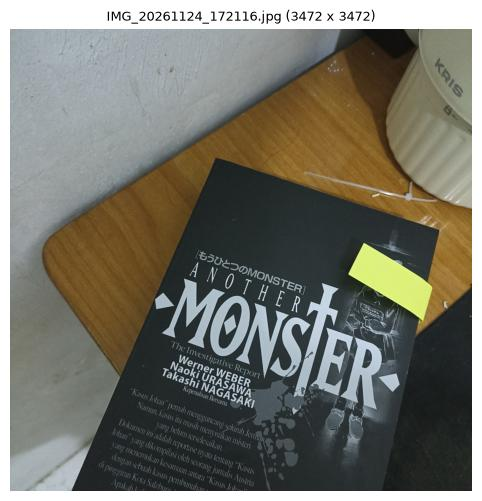

In [13]:
from iiss.data.images import load_image

for path in demo.list_images(IMAGE_PATH)[: 1 if SMOKE else None]:
    image = load_image(path)
    plt.figure(figsize=(6, 6))
    plt.title(f"{path.name} ({image.width} x {image.height})", fontsize=9)
    image.thumbnail((demo.MAX_SIDE, demo.MAX_SIDE))
    plt.imshow(image)
    plt.axis("off")
    plt.show()

## Predict

Keeps the raw predictions (score of at least `demo.MIN_SCORE`) in memory.

In [14]:
photos = demo.list_images(IMAGE_PATH)
photos = photos[:1] if SMOKE else photos
results = [demo.predict_photo(models, p, names) for p in photos]
print(len(results), "photos,", len(models), "models")

1 photos, 3 models


## Show

Fill color = class (same in all panels of a photo). Figures go to `OUT_DIR`.

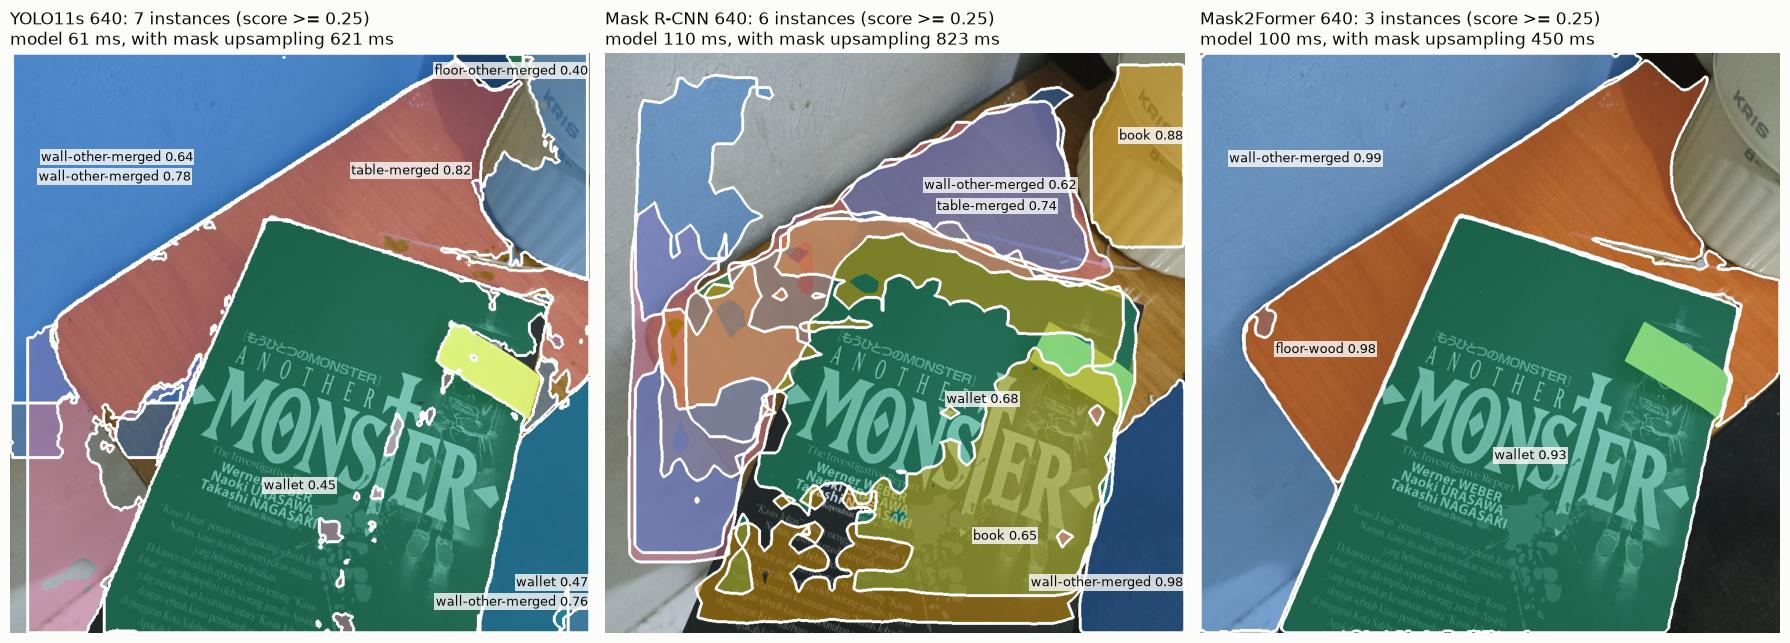

,photo,size,run_id,instances,classes,model_ms,total_ms
0,IMG_20261124_172116.jpg,3472x3472,yolo_s640_seed42,7,"wall-other-merged x3, wallet x2, table-merged, floor-other-merged",61,621
1,IMG_20261124_172116.jpg,3472x3472,maskrcnn_s640_seed42,6,"wall-other-merged x2, book x2, table-merged, wallet",110,823
2,IMG_20261124_172116.jpg,3472x3472,m2f_s640_seed42,3,"wall-other-merged, floor-wood, wallet",100,450


In [15]:
# THRESHOLD = SCORE_THRESHOLD
THRESHOLD = 0.25

for result in results:
    demo.plot_photo(result, THRESHOLD, OUT_DIR)
    plt.show()
demo.summary_table(results, THRESHOLD)

## Per-class AP

Mask AP x 100 from `results/eval/`, nothing is computed again. Only classes with ground truth in the set; the row `mean` is the reported AP.

In [16]:
AP_RUNS = RUNS  # e.g. ['yolo_s320', 'yolo_s640', 'yolo_s960']
EVAL_SET = "phone"  # valid, test or phone

demo.per_class_ap(AP_RUNS, EVAL_SET)

,n_gt,yolo_s640_seed42,maskrcnn_s640_seed42,m2f_s640_seed42
name,,,,
wall-other-merged,47,19.4,21.3,21.1
table-merged,18,38.2,28.3,16.7
pillow,13,1.3,0.8,34.3
floor-other-merged,12,12.6,9.6,24.7
chair,11,0.0,0.7,9.9
bottle,8,45.3,43.3,62.4
food-other-merged,8,0.0,0.0,0.4
towel,8,0.0,1.4,3.2
bed,7,0.0,0.2,27.4


## Scores per object

One row per detected object, at the `THRESHOLD` of **Show**. Nothing is predicted again.

- `score`: confidence of the model. `class_AP`: mask AP x 100 of the class on `AP_SET`.
- `result`: `matched` (right class, IoU of at least 0.5), `wrong_class`, `poor_mask`, `duplicate`, or `no_gt` (nothing annotated there).
- `iou`, `mask_precision`, `mask_recall`: the mask against `gt_object`, which is the matched object or else the annotated object with the highest IoU (at least 0.1).
- Photos without annotations show `not annotated` and have no IoU.

In [ ]:
AP_SET = "phone"  # valid, test or phone

demo.object_scores(results, THRESHOLD, AP_SET)

Ground truth next to the models. White outline = ground truth or matched prediction, black outline = prediction without a match. The table counts one photo at one threshold, so it is not AP.

In [ ]:
for result in results:
    if demo.plot_scores(result, THRESHOLD, OUT_DIR):
        plt.show()
demo.photo_scores(results, THRESHOLD)

One row per annotated object, including the ones a model misses: best IoU within the class and the tag of the failure analysis.

In [ ]:
demo.gt_scores(results, THRESHOLD)

## Input size 320, 640, 960

The same photos with every input size. Models that are not loaded yet are loaded one at a time and removed again. Change `SIZE_MODELS` to one model for a faster run.

In [ ]:
SIZE_MODELS = ["yolo", "maskrcnn", "m2f"]
SIZES = [320] if SMOKE else [320, 640, 960]

size_results = demo.predict_sizes(SIZE_MODELS, SIZES, photos, names, loaded=models)
print(len(size_results), "rows of", len(SIZES), "input sizes")

One row per model, one panel per input size.

In [ ]:
for result in size_results:
    demo.plot_photo(result, THRESHOLD, OUT_DIR)
    plt.show()
demo.summary_table(size_results, THRESHOLD)

The same comparison against the ground truth (photos without annotations are left out).

In [ ]:
for result in size_results:
    if demo.plot_scores(result, THRESHOLD, OUT_DIR):
        plt.show()
demo.photo_scores(size_results, THRESHOLD)

IoU and tag of every annotated object per input size, then every detected object.

In [ ]:
demo.gt_scores(size_results, THRESHOLD)

In [ ]:
demo.object_scores(size_results, THRESHOLD, AP_SET)